In [220]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
from skimage.morphology import skeletonize

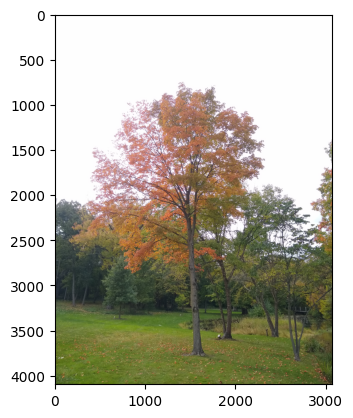

In [221]:
img_original = cv.imread("resource/test_images/deciduous_1.jpg")
img_original = cv.cvtColor(img_original, cv.COLOR_BGR2RGB)
plt.imshow(img_original)

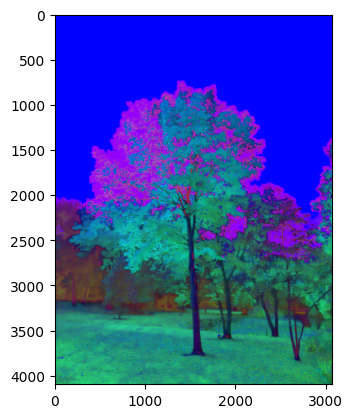

In [222]:
img_hsv = cv.cvtColor(img_original, cv.COLOR_RGB2HSV)
plt.imshow(img_hsv)

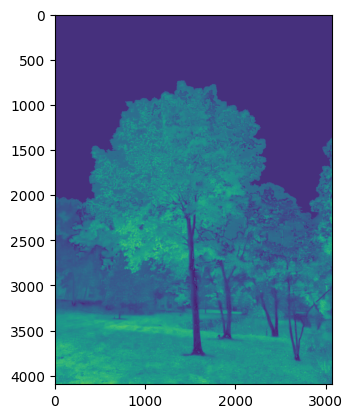

In [223]:
img_gray = cv.cvtColor(img_hsv, cv.COLOR_RGB2GRAY)
plt.imshow(img_gray)

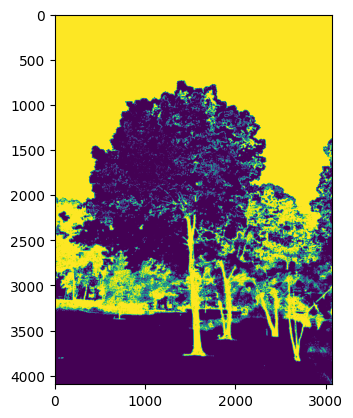

In [224]:
ret, img_bin = cv.threshold(img_gray, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)
plt.imshow(img_bin)

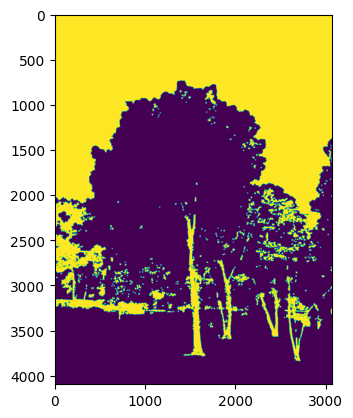

In [225]:
kernel = cv.getStructuringElement(cv.MORPH_RECT, (3, 3)) 
img_filtered = cv.morphologyEx(img_bin,  
                           cv.MORPH_OPEN, 
                           kernel, 
                           iterations=5) 
plt.imshow(img_filtered)

In [226]:
# img_skeleton = skeletonize(img_filtered)
# plt.imshow(img_skeleton)

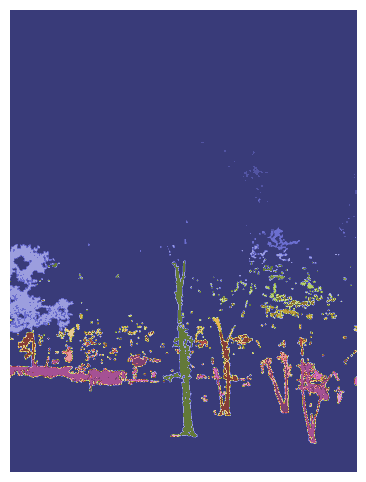

In [227]:
n_labels, labels, stats, centroids = cv.connectedComponentsWithStats(img_filtered)
fig, ax = plt.subplots(figsize=(6, 6)) 
ax.imshow(labels, cmap="tab20b") 
ax.axis('off') 
plt.show()

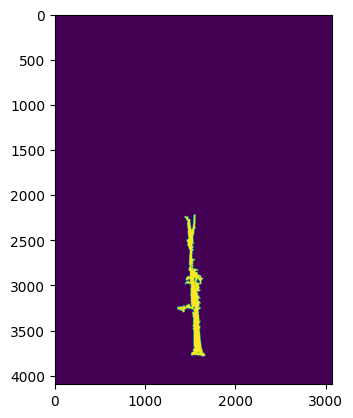

In [258]:
min_i = None
min_d = None

largest = np.argsort([stats[i, cv.CC_STAT_HEIGHT] for i in range(0, n_labels)])[::-1]

for i in largest[:10]:
    h = stats[i, cv.CC_STAT_HEIGHT]
    w = stats[i, cv.CC_STAT_WIDTH]
    t = stats[i, cv.CC_STAT_TOP]
    l = stats[i, cv.CC_STAT_LEFT]
    a = stats[i, cv.CC_STAT_AREA]

    dy = (t + h) - img_original.shape[0]
    dx = l - (img_original.shape[1] / 2)
    d = dy**2 + dx**2

    if (min_d is None) or (d < min_d):
        min_d = d
        min_i = i


mask = labels.copy()
mask[mask != min_i] = 0
mask = mask.astype(np.uint8)
h = stats[min_i, cv.CC_STAT_HEIGHT]
w = stats[min_i, cv.CC_STAT_WIDTH]
t = stats[min_i, cv.CC_STAT_TOP]
l = stats[min_i, cv.CC_STAT_LEFT]
plt.imshow(mask)

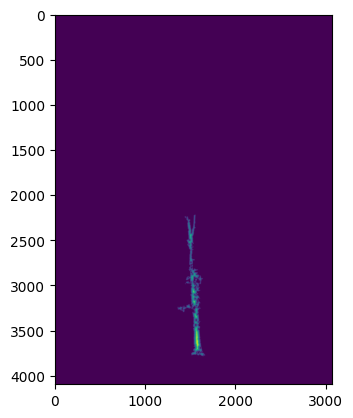

In [267]:
dist = cv.distanceTransform(mask, cv.DIST_L2, 5)
plt.imshow(dist)

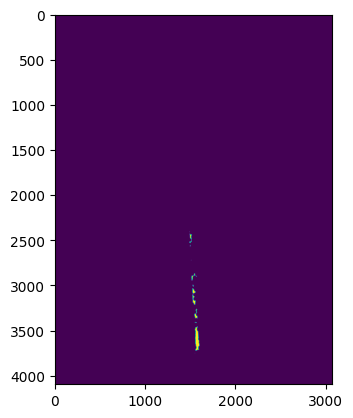

In [268]:
ret, marks = cv.threshold(dist, 0.5 * dist.max(), 255, cv.THRESH_BINARY)
plt.imshow(marks)

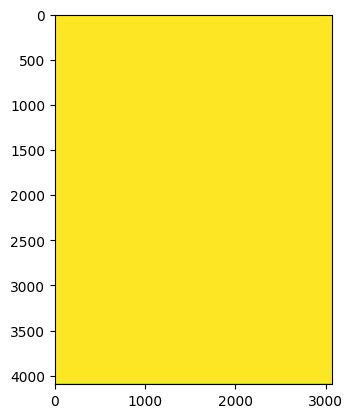

In [271]:
tree_mask = cv.watershed(img_original, img_filtered.astype(np.int32))
plt.imshow(tree_mask)